# Magic-state cultivation (d = 3 and d = 5): what the tool finds

> **In short.**
> * **The setting.** Fault-tolerant quantum computers need *magic states* such as $T^\dagger|+\rangle$ to apply $T$ gates. Cultivation makes a good one inside a small error-correcting code and checks it repeatedly; a run whose checks disagree is thrown away.
> * **The questions.** Which code are the qubits in after each stage? Which parities of measurement results are fixed (the *detectors*)? What does the whole circuit prepare, in every run?
> * **The answers, from the gates alone.** The [[7,1,3]] colour code (at d = 5, [[19,1,5]]); exactly the detectors the circuit's authors wrote (26 at d = 3, 89 at d = 5), no more and no fewer; and $T^\dagger|+\rangle$ in the code in every run, up to a $Z$ correction on a known parity of results. The double-check is a measurement of the protected qubit in the basis $\{T^\dagger|+\rangle, T^\dagger|-\rangle\}$. Part 5 checks the d = 3 answers with a state-vector simulator that uses no ZX at all.
> * **How to read the pictures.** In the circuit pictures lines are qubits and time runs left to right; green and red dots are Z- and X-spiders, `π/4` on a green dot is a $T$, `7π/4` a $T^\dagger$, and a red dot with a phase `c[...]` is a measurement and its result. Part 4 draws the simplification step by step; the 3D pictures put each qubit at its place on the code's triangle.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

**Cultivation** makes a good magic state by checking it. A T-type state is prepared inside a small code (here the 7-qubit colour code, which is the Steane code), and then *measured in its own basis*. If the state is right, the measurement gives the answer that earlier outcomes predict. Under noise, a wrong answer means the state is bad and the run is thrown away.

This notebook runs the three questions of the paper on the d = 3 cultivation circuit of Wan, Zhong and Zapirain (*Simulating magic state cultivation with few Clifford terms*, Quantum 10, 2134 (2026)), which follows Gidney, Shutty and Jones (arXiv:2409.17595). The circuit is copied unchanged from the authors' repository (Apache-2.0); see `circuits/cultivation/README.md`.

Part 4 draws the reduction step by step and checks every picture against the circuit diagram. Part 5 checks the tool's claims against an independent state-vector simulation of the same circuit, which involves no ZX at all. Part 6 asks the same questions of a d = 5 cultivation circuit with real T gates (42 qubits), which grows the code from d = 3 to d = 5.

In [1]:
%matplotlib inline
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')                       # for the test suite's state-vector simulator (Part 5)
from zxqec.qprogram import program_from_stim
from zxqec.gpf import reduce_gpf, is_leaf

text = open('circuits/cultivation/d3_cultivation.stim').read()
p, circ = program_from_stim(text, names=['first checks', 'inject', 'checks again',
                                         'double-check (T-dag, measure)', 'double-check (T, measure)'])
print(circ.qubits, "qubits,", circ.measurements, "measurements,", len(circ.detectors),
      "detectors written by the authors,", p.num_stages, "stages")
for s in range(p.num_stages):
    print("  stage", s, p.stage(s))

18 qubits, 31 measurements, 26 detectors written by the authors, 5 stages
  stage 0 first checks
  stage 1 inject
  stage 2 checks again
  stage 3 double-check (T-dag, measure)
  stage 4 double-check (T, measure)


The file is in Stim's text format, with `T` and `T_DAG` added. `program_from_stim` turns it into a program. It starts a new stage wherever a measured qubit is reset, so every measurement ends a stage.

The authors' `DETECTOR` lines are **not** used to build the program. They are kept aside, so that we can compare them with the detectors the tool derives by itself.

The circuit, one shade per stage: the first checks, the injection, the checks again, and the two halves of the double-check, with its $T^\dagger$ layer (`7π/4`) and $T$ layer (`π/4`) on the seven code qubits. Part 4 draws the same circuit as one ZX-diagram and simplifies it.

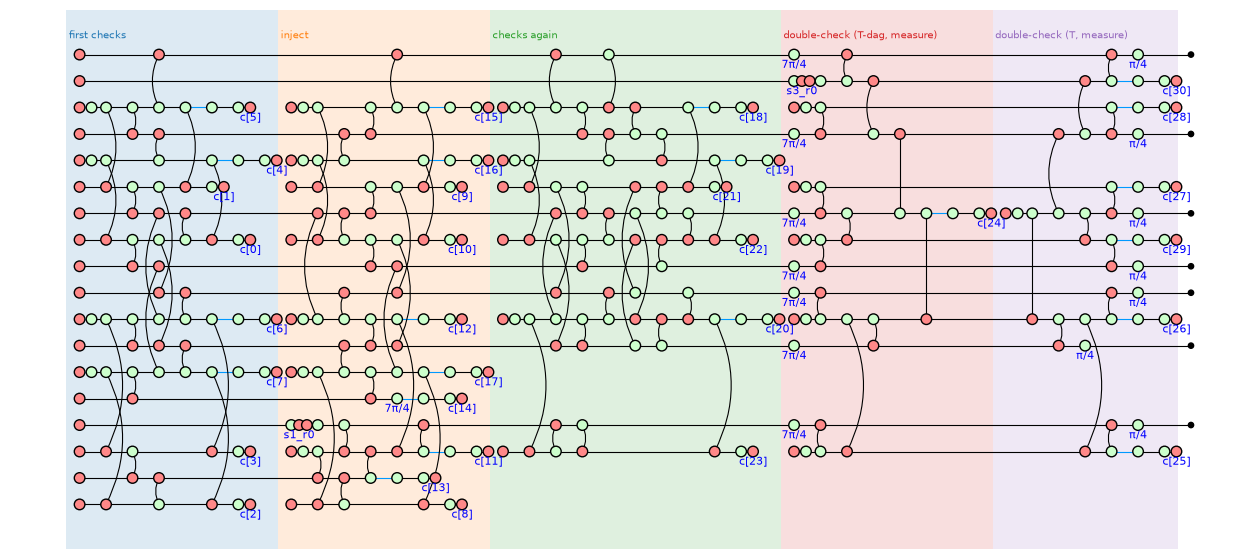

In [2]:
from zxqec.spacetime import draw_program
draw_program(p, level=0, show_time=False, labels=False, figsize=(16, 7))

## Part 1. Question 1: which code, after each stage?

In [3]:
for s in range(p.num_stages):
    code = p.code_at(s)
    parts = ["[[{},{},{}]] on qubits {}{}".format(*b.parameters, list(b.qubits),
             "  (non-Clifford logical state)" if b.non_clifford else "") for b in code.blocks()]
    print("after stage {} ({}):".format(s, p.stage(s)))
    for part in parts:
        print("    " + part)

after stage 0 (first checks):
    [[8,0,None]] on qubits [0, 3, 6, 8, 9, 11, 13, 16]
after stage 1 (inject):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (non-Clifford logical state)
after stage 2 (checks again):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (non-Clifford logical state)
after stage 3 (double-check (T-dag, measure)):
    [[12,3,2]] on qubits [0, 1, 2, 3, 5, 7, 8, 9, 10, 11, 14, 15]  (non-Clifford logical state)
after stage 4 (double-check (T, measure)):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (non-Clifford logical state)


* After the **first checks** the helpers and the future code qubits are in a stabilizer state with no logical qubit (`k = 0`).
* After the **injection** the data are in a **[[7,1,3]]** code holding a non-Clifford logical state. That is the colour code with the magic state inside, found from the gates.
* After the **first half of the double-check** the tool reports a strange [[12,3,2]]. This cut falls in the middle of a T†…T sandwich, where the state is not a code state in any useful sense. That is why the double-check is grouped as one block in Part 3.
* After the **double-check** it is the [[7,1,3]] code again.

The stabilizers at the end, with signs that are measurement outcomes:

In [4]:
print(p.code_at(p.num_stages - 1).data())

[[7, 1, 3]] CSS code on qubits 0, 3, 6, 8, 9, 11, 14 (holding a non-Clifford logical state)
    stabilizer (-1)^(c[4])XIIXXXI
    stabilizer (-1)^(c[27])IIXIXXX
    stabilizer (-1)^(c[28] + c[5])IXIXXIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII


## Part 2. The detectors, and why two of them need the T gates

A *detector* is a parity of outcomes that is 0 in every noiseless run. The authors wrote 26 by hand. The tool derives its own; the next cell compares the two sets as spaces of parities.

In [5]:
from zxqec.codes.gf2 import as_matrix, rank

def span(polys, names):
    rows = []
    for d in polys:
        v = np.zeros(len(names) + 1, dtype=np.uint8)
        if isinstance(d, list):
            for n in d: v[names.index(n)] ^= 1
        else:
            for coeff, term in d.terms:
                if int(coeff) % 2:
                    if term.vars: v[names.index(term.vars[0][0].name)] ^= 1
                    else: v[-1] ^= 1
        rows.append(v)
    return as_matrix(rows, len(names) + 1)

names = ['c[{}]'.format(i) for i in range(circ.measurements)]
theirs = span(circ.detectors, names)
for gadgets in (False, True):
    res = reduce_gpf(p.quantum_graph(), gadgets=gadgets)
    on_outcomes = [d for d in res.detectors if all(str(v).startswith('c[') for v in d.free_vars())]
    ours = span(on_outcomes, names)
    missed = [i for i, d in enumerate(circ.detectors) if rank(np.concatenate([ours, span([d], names)])) > rank(ours)]
    extra = rank(np.concatenate([ours, theirs])) - rank(theirs)
    h = res.graph
    print("gadget layer simplified: {:<5} -> {} detectors on outcomes; authors' detectors not found: {}; "
          "ours not among theirs: {}; T-type gadgets left: {}".format(
          str(gadgets), rank(ours), [circ.detectors[i] for i in missed] or 'none', extra,
          sum(1 for v in h.vertices() if is_leaf(h, v))))
print("other constraints the tool reports:", [str(d) for d in res.detectors if d not in on_outcomes])

gadget layer simplified: False -> 24 detectors on outcomes; authors' detectors not found: [['c[2]', 'c[3]', 'c[5]', 'c[7]', 'c[8]', 'c[10]', 'c[11]', 'c[13]', 'c[14]', 'c[19]', 'c[20]', 'c[24]'], ['c[27]', 'c[24]']]; ours not among theirs: 0; T-type gadgets left: 15


gadget layer simplified: True  -> 26 detectors on outcomes; authors' detectors not found: none; ours not among theirs: 0; T-type gadgets left: 1
other constraints the tool reports: ['s3_r0', 's1_r0']


Reading the two lines:

* With only Clifford reasoning (first line), the tool finds **24 of the 26**. The two it misses both contain `c[24]`, the outcome of the double-check. They hold only because the T† gates before the check and the T gates after it cancel. A reduction that treats the 15 T-type gadgets as fixed cannot see that.
* With the **gadget layer simplified** (second line, the default), all 26 are found and nothing else. The 15 gadgets shrink to one.
* The last line lists two constraints on PyZX's *reset variables*. They say that resetting a qubit already in |0⟩ discards the value 0: true, and not about any measurement.

The gadget layer is simplified like a triorthogonality check. Each T-type gadget adds a phase that depends on the parity of some bits of the diagram. Adding all of them gives one polynomial in those bits, with coefficients modulo 2π, and this polynomial describes the whole layer exactly.

* When T† and T gates cancel, their terms cancel in the polynomial. For π/4 gadgets, "cancel" is exactly the triorthogonality condition: weights 0 mod 8, pair overlaps 0 mod 4, triple overlaps 0 mod 2.
* A bit that no term depends on any more is free again. The ordinary row reduction then turns it into a detector: here, the two missing ones.

This is a computation on a polynomial, not a search for rewrite rules. Here it leaves:

### The same check as one call

`check_detectors` compares declared detectors with the derived ones for any program. Each declared detector gets one of three answers:

* **deterministic**: it is a sum of derived detectors, so it has the same value in every noiseless run (the value is printed);
* **not deterministic**: two runs that the program allows give it different values (the two runs are returned as evidence);
* **unknown**: neither could be shown. With the gadgets held fixed, the tool does not derive the two detectors that need the T gates, and it does not find a run that breaks them either, so it does not call them wrong.

The last lines leave one result out of a declared detector, to show what a wrong detector looks like.

In [6]:
from zxqec.qprogram import check_detectors

print(check_detectors(p, circ.detectors))
print()
print(check_detectors(p, circ.detectors, gadgets=False))
print()
wrong = [list(d) for d in circ.detectors]
wrong[9] = [x for x in wrong[9] if x != 'c[12]']          # detector 9 without c[12]
bad = check_detectors(p, wrong).declared[9]
print(bad)
print("its values in the two runs returned as evidence:", [sum(run[n] for n in bad.results) % 2 for run in bad.witness])

26 declared detector(s): 26 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 26 independent detectors on its results, all sums of declared ones



26 declared detector(s): 24 deterministic (value 0), 0 not deterministic, 2 unknown
  detector 19: c[2] + c[3] + c[5] + c[7] + c[8] + c[10] + c[11] + c[13] + c[14] + c[19] + c[20] + c[24] is not a sum of the derived detectors, and no two allowed runs with different values were found: unknown
  detector 22: c[27] + c[24] is not a sum of the derived detectors, and no two allowed runs with different values were found: unknown
the program has 24 independent detectors on its results, all sums of declared ones

detector 9: c[13] + c[6] is NOT deterministic: it is 0 in one allowed run and 1 in another
its values in the two runs returned as evidence: [0, 1]


In [7]:
from zxqec.gpf import phase_polynomial
h = reduce_gpf(p.quantum_graph()).graph
poly, gadgets = phase_polynomial(h)
print("phase polynomial of what is left (units of pi):",
      {tuple(sorted(str(v[1]) if isinstance(v, tuple) else v for v in m)): str(c) for m, c in poly.items()})
for v in h.vertices():
    if is_leaf(h, v):
        (hub,) = list(h.neighbors(v))
        print("one gadget: angle", h.phase(v), "(pi units), on the parity of", len(list(h.neighbors(hub))) - 1, "spiders")

phase polynomial of what is left (units of pi): {('348',): '7/4', ('350',): '7/4', ('351',): '7/4', ('348', '350'): '1/2', ('348', '351'): '1/2', ('350', '351'): '1/2', ('348', '350', '351'): '1'}
one gadget: angle 7/4 (pi units), on the parity of 3 spiders


A single T† gadget on a parity of three spiders: the magic state itself.

## Part 3. Questions 2 and 3: the level-up table

Grouped the way the protocol is described: first checks, injection, a round of checks, and the double-check as one block.

In [8]:
fine = p.group_stages([(0, 0, 'first checks', 'state preparation'), (1, 1, 'inject T', 'injection'),
                       (2, 2, 'checks', 'syndrome extraction'), (3, 4, 'double-check', 'cultivation')])
s = p.summary(fine)
print(s.table()); print(); print(s.blocks[3].describe())

block           role                 code before  code after  logical action                                   every run?  checks
0 first checks  state preparation    none         [[8,0,?]]   a non-zero scalar                                yes         ok
1 inject T      injection            [[8,0,?]]    [[7,1,3]]   prepares T^dag|+>                                yes         ok
2 checks        syndrome extraction  [[7,1,3]]    [[7,1,3]]   I                                                yes         ok
3 double-check  cultivation          [[7,1,3]]    [[7,1,3]]   projects onto T^dag|+> / projects onto T^dag|->  no          ok

Block 3 'double-check' (cultivation) -- stages 3, 4
  code before: [[7,1,3]] on qubits 0,3,6,8,9,11,14 (non-Clifford logical content)
  code after:  [[7,1,3]] on qubits 0,3,6,8,9,11,14 (non-Clifford logical content)
  logical action: a logical measurement in the basis {T^dag|+>, T^dag|->}: T^dag|+> when c[24] = 0; T^dag|-> when c[24] = 1
  measurements: 7 (4 fixe

* **inject T** prepares T†|+⟩ in the code, in every run up to a Pauli correction.
* **checks** do nothing to the logical state, as checks should.
* **double-check** is a *logical measurement in the basis {T†|+⟩, T†|−⟩}*, whose outcome is `c[24]`. Its "every run?" is "no", because a measurement's outcome can differ between runs, and that is expected.

The measurement report explains why the check is useful. In this program, `c[24]` is *tied*: its parity with the injection outcomes `c[4], c[5], c[6], c[7], c[14]` is always 0. Those are exactly the outcomes that decide whether the injected state is T†|+⟩ or T†|−⟩. So the check measures the state in its own basis and always gets the predicted answer. Under noise, a different answer means the state went wrong, and the run is discarded. The tool reports this as the check "can reject a wrong state".

This is what we understand by *deterministic vs non-deterministic* in cultivation: `c[24]` alone is random, but its parity with earlier outcomes is deterministic.

One level up, the whole circuit is one block:

In [9]:
whole = p.level_up(fine, 0, 3, name='cultivation', role='state preparation')
print(p.summary(whole).table())
print()
print(p.logical_action().describe())

block          role               code before  code after  logical action     every run?  checks
0 cultivation  state preparation  none         [[7,1,3]]   prepares T^dag|+>  yes         ok



logical action: 0 -> 1 logical qubit(s)
  when c[5] + c[4] + c[6] + c[7] + c[14] = 0: prepares T^dag|+>
  when c[5] + c[4] + c[6] + c[7] + c[14] = 1: prepares T^dag|+> with correction Z
  deterministic up to a Pauli frame: every run implements prepares T^dag|+> followed by a Pauli correction (Z, none) that the outcomes determine


**In every noiseless run, the circuit prepares T†|+⟩ in the [[7,1,3]] colour code**, followed by a Z correction exactly when `c[4] + c[5] + c[6] + c[7] + c[14] = 1`. A Pauli correction like this is tracked, not applied. This holds in every run, not just the one with all outcomes 0.

## Part 4. The same result, drawn step by step

Part 3 gives the verdict as text. This part shows how the diagram gets there: the whole circuit as a ZX-diagram, the diagram after each step of the reduction, and at the end the diagram we expect, **T†|+⟩ fed into the encoder of the colour code**. The last two pictures can be compared by eye.

Each picture is also checked against the circuit. The detectors fix 28 of the 33 Boolean variables (31 outcomes and 2 reset variables) in terms of the other 5, so exactly 32 runs can happen. For every picture and every one of these runs, PyZX contracts the picture and the circuit diagram to matrices, and the two must be equal up to a scalar. That check uses tensor contraction only, none of the rewrites it checks.

The pictures are PyZX's own drawings (`zx.draw_matplotlib`) of the library's layout of a normal form (`layout_gpf`: the Z-layer on the left, the X-layer on the right, gadgets below the outputs). Outcomes in the phases are written *modulo the detectors* (`phases_modulo`), in the earliest outcomes possible. For example `c[27]` is shown as `c[4] + c[5] + c[6] + c[7] + c[14]`, which it equals in every run. So two pictures that are equal carry the same labels.

In [10]:
import pyzx as zx
from IPython.display import display
from pyzx.utils import VertexType
from zxqec.gpf import (to_gpf, layout_gpf, boolean_variables, restore_boundary_hadamards, phase_polynomial,
                       change_variables, consistent_assignments, equal_for_all_assignments, phases_modulo)
from zxqec.spacetime.drawing import draw_program

g = p.quantum_graph()                                  # the circuit as one ZX-diagram
res = reduce_gpf(g)
code = p.code_at(p.num_stages - 1).data()              # the [[7,1,3]] code of Part 1
variables = sorted(set(boolean_variables(g)) | {str(v) for c in res.constraints for v in c.free_vars()})
runs = consistent_assignments(res.constraints, variables)
print(len(variables), "Boolean variables;", len(runs), "runs allowed by the detectors")

def same_as_circuit(h):
    # equal to the circuit diagram, up to a scalar, in every allowed run (tensor contraction)
    return equal_for_all_assignments(g, h, variables, res.constraints)

def spiders(h):
    return sum(1 for v in h.vertices() if h.type(v) != VertexType.BOUNDARY)

33 Boolean variables; 32 runs allowed by the detectors


### Step 0. The whole circuit

370 spiders on 18 qubits, one shaded block per stage. The T† and T gates are the spiders with phases 7π/4 and π/4, and every measurement ends in a spider labelled with its outcome.

370 spiders


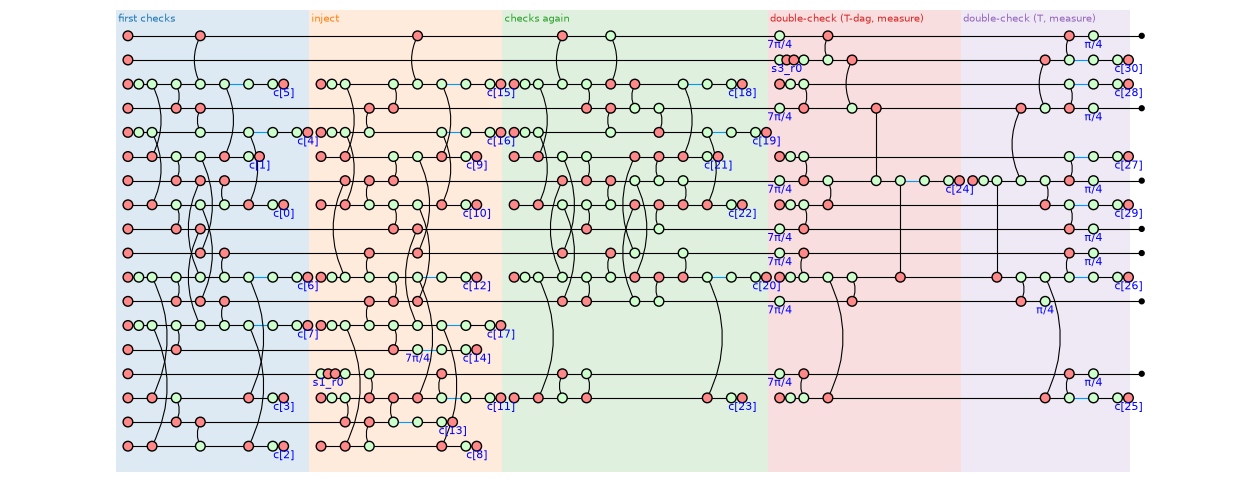

In [11]:
print(f"{spiders(g)} spiders")
draw_program(p, 0, figsize=(16, 6), show_time=False)

### Step 1. The normal form

`to_gpf` brings the diagram into two layers (the generalized parity form). On the left are the Z-spiders, whose bits are summed over; on the right one X-spider per output qubit. Each T-type gate has become a **phase gadget**: an X-spider (the hub) with a one-legged Z-spider carrying the phase, which acts on the parity of the Z-spiders the hub is connected to. There are 15, one per T-type gate: 7 T† and 7 T from the double-check, and the T† of the injection, whose leaf also carries the outcome `c[14]`.

The 24 detectors that hold without any help from the T gates are already found at this point: they are the factors 1 + (−1)^p left in the scalar when spiders lose their last edge.

43 spiders, 15 gadgets


equal to the circuit in all 32 runs: True


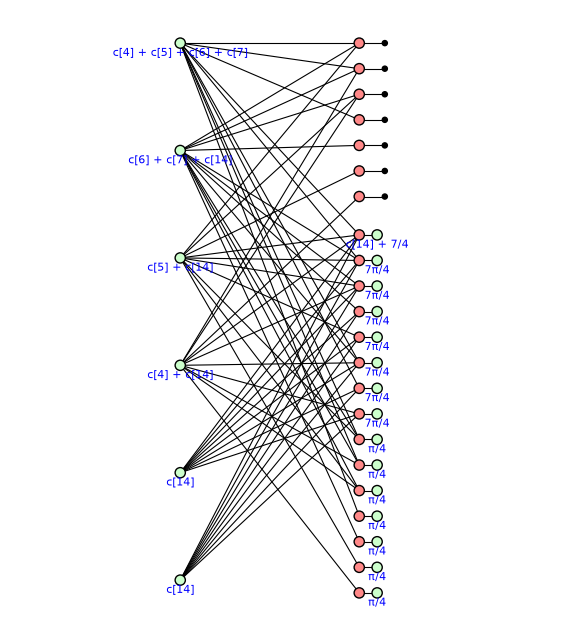

In [12]:
d1 = to_gpf(g)
print(f"{spiders(d1)} spiders, {sum(1 for v in d1.vertices() if is_leaf(d1, v))} gadgets")
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(restore_boundary_hadamards(d1)))
zx.draw_matplotlib(phases_modulo(d1, res.constraints), figsize=(7, 8))

### Step 2. The 15 gadgets in the code's variables

When a layer of ±π/4 gadgets on the physical qubits of a code can be replaced by a layer on its logical qubits. Write the parity each gadget reads in the code's variables, the k logical columns first and the stabilizer columns after; these are the rows of a matrix M. A gadget on the physical qubits has a row (P_L P_S), a gadget on the logical qubits a row (H 0). The layer (P_L P_S) equals the layer (H 0) with the opposite signs exactly when all of them together are the identity, which for π/4 gadgets is a triorthogonality condition on M.

This step can be reached by inserting spider-nest identities by hand; the tool instead adds the gadgets up as one phase polynomial (Part 2). For π/4 gadgets its coefficients mod 2 are exactly the counts of the triorthogonality condition (weights mod 8, pair overlaps mod 4, triple overlaps mod 2), so one pass over the gadgets decides it and gives H.

To see this on cultivation, change the summation variables of step 1 (`change_variables`, as step 4 below does for the reduced diagram) so that the Z-layer is the code's logical X (`L`), its three X-type generators (`S1`, `S2`, `S3`), and two **hidden** variables (`h1`, `h2`). The normal form has six Z-spiders but only four independent rows on the outputs, so two combinations of them reach no output at all: those are the hidden variables.

equal to the circuit in all 32 runs: True
the Z-spiders (vertex numbers in the picture): {'L': 307, 'S1': 319, 'S2': 348, 'S3': 349, 'h1': 350, 'h2': 351}


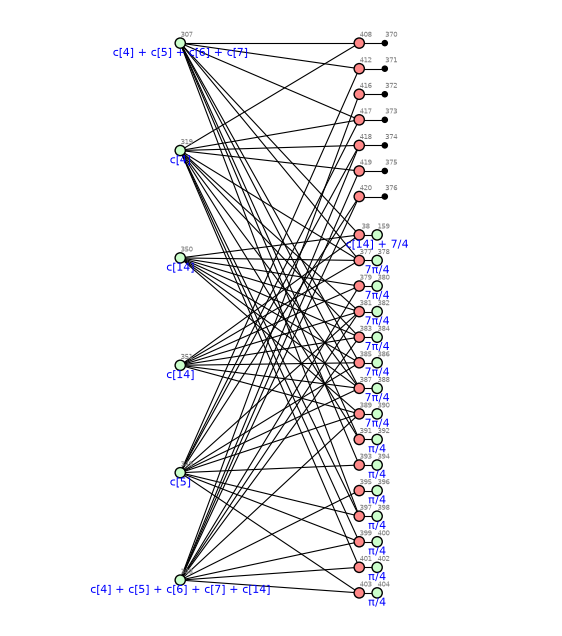

the rows of M, one per gadget, in the variables  L | S1 S2 S3 | h1 h2:
    c[14] + 7/4   1 | 0 0 0 | 1 1
            7/4   1 | 1 0 0 | 1 1
            7/4   0 | 0 1 0 | 1 1
            7/4   0 | 1 1 1 | 1 1
            7/4   0 | 1 1 0 | 1 1
            7/4   1 | 0 0 1 | 1 1
            7/4   1 | 1 0 1 | 1 1
            7/4   0 | 0 1 1 | 1 1
            1/4   1 | 1 0 0 | 0 0
            1/4   1 | 0 0 1 | 0 0
            1/4   0 | 0 1 0 | 0 0
            1/4   1 | 1 0 1 | 0 0
            1/4   0 | 1 1 1 | 0 0
            1/4   0 | 1 1 0 | 0 0
            1/4   0 | 0 1 1 | 0 0
the 7 T gates read the 7 columns of the code: True
the 7 T-dagger gates read the same 7 columns, and h1 + h2: True


In [13]:
from fractions import Fraction
from zxqec.gpf.gadgets import _xor_terms

rows = [list(code.logical_x[0].x)] + [list(r) for r in code.sx]
m1 = change_variables(d1, rows, fuse=False)                    # step 1 in the code's variables
zs1 = sorted(v for v in m1.vertices() if m1.type(v) == VertexType.Z and not is_leaf(m1, v))
var = dict(zip(zs1, ['L', 'S1', 'S2', 'S3', 'h1', 'h2']))
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(m1))
print("the Z-spiders (vertex numbers in the picture):", {name: v for v, name in var.items()})
display(zx.draw_matplotlib(phases_modulo(m1, res.constraints), labels=True, figsize=(7, 8)))

gadget_rows = []
print("the rows of M, one per gadget, in the variables  L | S1 S2 S3 | h1 h2:")
for leaf in sorted(v for v in m1.vertices() if is_leaf(m1, v)):
    (hub,) = list(m1.neighbors(leaf))
    r = tuple(int(m1.connected(hub, z)) for z in zs1)
    gadget_rows.append((str(m1.phase(leaf)), r))
    print("   {:>12}   {} | {} | {}".format(str(m1.phase(leaf)), r[0], ' '.join(map(str, r[1:4])), ' '.join(map(str, r[4:]))))

columns = {tuple(int(row[j]) for row in rows) for j in range(code.n)}     # (P_L P_S) of each code qubit
t_rows = {r[:4] for a, r in gadget_rows if a == '1/4'}
t_dag_rows = {r[:4] for a, r in gadget_rows if a == '7/4' and r[4:] == (1, 1)}
print("the 7 T gates read the 7 columns of the code:", t_rows == columns)
print("the 7 T-dagger gates read the same 7 columns, and h1 + h2:", t_dag_rows == columns)

So the **7 T gates** of the double-check read the seven columns (P_L P_S) of the code, one per code qubit: that is transversal T. The **7 T† gates** read the same seven columns and also `h1 + h2`. The **T† of the injection** reads `L`, and also `h1 + h2`; its leaf carries the outcome `c[14]`.

Adding the 15 gadgets up:

In [14]:
poly, _ = phase_polynomial(m1)
name = lambda v: var[v[1]] if isinstance(v, tuple) else v
pauli = {m: c for m, c in poly.items() if c == 1 and sum(isinstance(v, tuple) for v in m) == 1}
rest = {m: c for m, c in poly.items() if m not in pauli}
print("phase polynomial apart from Pauli terms (units of pi):",
      {'*'.join(sorted(map(name, m))): str(c) for m, c in rest.items()})
print("the same as one T-dagger gadget on L alone, i.e. H = (1):", rest == _xor_terms([('z', zs1[0])], Fraction(7, 4)))
print("Pauli terms:", sorted('*'.join(sorted(map(name, m))) for m in pauli))
print()
for z in zs1[4:]:
    extra = ' + '.join(sorted(v for m in pauli if ('z', z) in m for v in m if not isinstance(v, tuple)))
    print("summing over {}: its phase is pi({}), plus pi({}) from above -> the detector {} + {} = 0".format(
        var[z], m1.phase(z), extra, m1.phase(z), extra))

phase polynomial apart from Pauli terms (units of pi): {'L': '7/4'}
the same as one T-dagger gadget on L alone, i.e. H = (1): True
Pauli terms: ['L*c[14]', 'c[14]*h1', 'c[14]*h2']

summing over h1: its phase is pi(c[24] + c[5] + c[4] + c[6] + c[7]), plus pi(c[14]) from above -> the detector c[24] + c[5] + c[4] + c[6] + c[7] + c[14] = 0
summing over h2: its phase is pi(c[5] + c[4] + c[6] + c[7] + c[27]), plus pi(c[14]) from above -> the detector c[5] + c[4] + c[6] + c[7] + c[27] + c[14] = 0


Everything cancels except 7π/4 on `L`: the 15 gadgets are **one T† gadget on the logical variable**, H = (1), plus the Pauli terms π·`c[14]`·(L + h1 + h2). The hidden variables are left with Pauli phases only, so their sums can be done: each gives 1 + (−1)^p, which is zero unless the parity p is 0. The two parities are the two detectors of Part 2 that need the T gates.

PyZX's own rewrite rules apply identities of bounded size, and do not find this cancellation:

In [15]:
import time
h0 = g.substitute_variables(runs[0])                             # one allowed run, outcomes fixed
t0 = time.perf_counter(); f = h0.copy(); zx.full_reduce(f); t_pyzx = time.perf_counter() - t0
t0 = time.perf_counter(); r1 = reduce_gpf(g); t_ours = time.perf_counter() - t0
print(f"PyZX full_reduce, one run:                  {zx.tcount(h0)} T-type gates -> {zx.tcount(f)}   ({t_pyzx * 1000:.0f} ms)")
print(f"reduce_gpf with the gadget step, all runs:  {sum(1 for v in d1.vertices() if is_leaf(d1, v))} gadgets -> "
      f"{sum(1 for v in r1.graph.vertices() if is_leaf(r1.graph, v))}   ({t_ours * 1000:.0f} ms)")

PyZX full_reduce, one run:                  15 T-type gates -> 15   (18 ms)
reduce_gpf with the gadget step, all runs:  15 gadgets -> 1   (36 ms)


### Step 3. The reduced diagram

What `reduce_gpf` returns: 4 Z-spiders, the 7 output X-spiders, and the single T† gadget.

13 spiders; 26 detectors on outcomes


equal to the circuit in all 32 runs: True


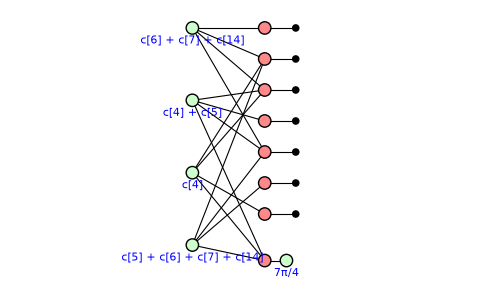

In [16]:
d2 = res.graph
outcome_detectors = [c for c in res.detectors if not any(v.name.startswith('s') for v in c.free_vars())]
print(f"{spiders(d2)} spiders; {len(outcome_detectors)} detectors on outcomes")
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(res.to_graph()))
zx.draw_matplotlib(phases_modulo(d2, res.constraints), figsize=(6, 3.5))

The 4 Z-spiders are one logical qubit and three X-type stabilizers of the code, but in a mixed basis: the T† gadget reads the parity of three of them.

### Step 4. A change of summation variables

The bits of the Z-spiders are summed over, so any invertible change of these variables gives the same map. We choose the one that makes the rows of the Z-layer the code's logical X (on qubits 0, 3, 8) and its three X-type generators, as printed in Part 1. The phases and the gadget follow the change (`change_variables`, the row operation of the split matrix). The gadget then reads the logical spider alone, and PyZX's identity-removal and fusion rules fuse it into that spider as a phase: this is the right-hand side, with H = (1).

In [17]:
rows = [list(code.logical_x[0].x)] + [list(r) for r in code.sx]
d3 = change_variables(d2, rows)
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(d3))

equal to the circuit in all 32 runs: True


### Step 5. The diagram we expect

Now build the expected diagram from the code alone, without the reduced diagram: the ideal encoder of the [[7,1,3]] code of Part 1 (`code.encoder()`), applied to T†|+⟩ followed by the Z correction of Part 3, i.e. `Z` when `c[4]+c[5]+c[6]+c[7]+c[14] = 1`. First step 4, then the expected diagram.

expected diagram equal to the circuit in all 32 runs: True
the code is self-dual (X and Z stabilizers on the same supports): True


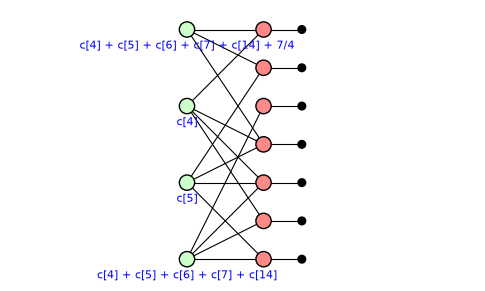

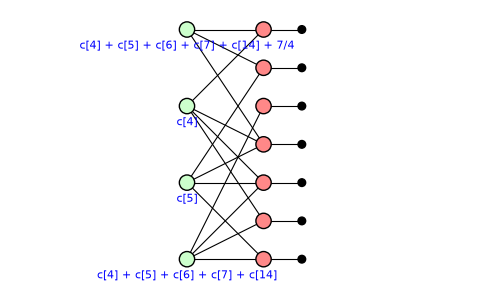

In [18]:
from pyzx.symbolic import new_var

d4 = code.encoder()                                    # the ideal encoder of the code, one input
(b,) = list(d4.inputs())
(z,) = list(d4.neighbors(b))
d4.remove_vertex(b)
d4.set_inputs(())
phase = Fraction(7, 4)                                 # T-dag|+>, then Z when c4 + c5 + c6 + c7 + c14 = 1
for name in ['c[4]', 'c[5]', 'c[6]', 'c[7]', 'c[14]']:
    phase = phase + new_var(name, True, d4.var_registry)
d4.set_phase(z, d4.phase(z) + phase)
layout_gpf(d4)
print("expected diagram equal to the circuit in all", len(runs), "runs:", same_as_circuit(d4))

from zxqec.codes import PauliString
swapped = [PauliString.from_arrays(s.z, s.x) for s in code.stabilizers]     # X <-> Z in every stabilizer
print("the code is self-dual (X and Z stabilizers on the same supports):", all(code.contains(s) for s in swapped))
display(zx.draw_matplotlib(phases_modulo(d3, res.constraints), figsize=(6, 3.5)))
display(zx.draw_matplotlib(phases_modulo(d4, res.constraints), figsize=(6, 3.5)))

The two pictures are the same: the logical spider carries 7π/4 (the T†) plus π times the correction parity, the three stabilizer spiders carry the signs of the checks, and the edges are the logical X and the three generators. A self-dual [[7,1,3]] CSS code is the Steane code up to the order of its qubits (its classical code is the [7,4,3] Hamming code), so this is the colour code of the paper.

| step | diagram | spiders | T-type gadgets | equal to the circuit in all 32 runs |
|---|---|---|---|---|
| 0 | the circuit | 370 | (15 T-type gates) | (itself) |
| 1 | normal form | 43 | 15 | yes |
| 2 | the same, in the code's variables | 43 | 15 | yes |
| 3 | reduced | 13 | 1 | yes |
| 4 | same, in the code's variables | 11 | 0 (fused into the logical spider) | yes |
| 5 | expected: T†\|+⟩ into the encoder | 11 | 0 | yes |

### Step 4 in 3D, next to the Steane code

From the two-layer picture of step 4 it is hard to see that this is the Steane code. Here the same diagram is drawn with the library's 3D view (`draw_graph_3d`, as for the fold-transversal Hadamard), on three planes. These heights are a layout of the reduced diagram, not time:

* **height 0**: the non-Clifford single-qubit states. The constant 7π/4 of the logical spider is split off as its own one-legged Z-spider (spider fusion read backwards): the state T†|+⟩;
* **height 1**: the logical spider, which carries the state;
* **height 2**: the code: the seven output X-spiders on the textbook triangle of the Steane code, and the other Z-spiders, each in the middle of the qubits it is wired to (the outputs end at height 3).

The plane at height 2 alone, flat (`draw_slice`), is the code without the state.

The triangle is the one of `TInjectionWalkthrough.ipynb`: qubits 0, 1, 2 at the corners, 3, 5, 6 in the middle of the sides and 4 in the centre, and the faces {0, 3, 4, 5}, {1, 3, 4, 6}, {2, 5, 4, 6}. To draw the circuit's qubits on it, we look for the orderings of the seven code qubits onto the triangle's qubits that put the three spiders wired to four qubits exactly on the three faces. Six orderings do, one for each way to give the three spiders to the three faces; we use the first. The spiders are named `L` (the one wired to three qubits, a logical X) and `S1`, `S2`, `S3` after the face they land on.

In [19]:
import itertools
from pyzx.graph import Graph
from zxqec.gpf import reduce_modulo
from teaching_figures import FACES, POS, COLORS

qubits = list(code.qubits)
out_x = [next(iter(d3.neighbors(b))) for b in d3.outputs()]
zs = sorted(v for v in d3.vertices() if d3.type(v) == VertexType.Z)
wired = {z: frozenset(j for j, w in enumerate(out_x) if d3.connected(z, w)) for z in zs}
stabs = [z for z in zs if len(wired[z]) == 4]
(logical,) = [z for z in zs if z not in stabs]
faces = [frozenset(f) for f in FACES]
orderings = [dict(zip(qubits, perm)) for perm in itertools.permutations(range(7))
             if {frozenset(perm[j] for j in wired[z]) for z in stabs} == set(faces)]
print(len(orderings), "of the 5040 orderings put the three weight-4 spiders on the three faces")
on = orderings[0]
print("the one used: circuit qubit -> triangle qubit", on)

spider_names = {wired[logical]: 'L'}
for z in stabs:
    spider_names[wired[z]] = 'S{}'.format(faces.index(frozenset(on[qubits[j]] for j in wired[z])) + 1)
print()
for z in [logical] + stabs:
    print("  {:3s} {:42s} circuit qubits {:16s} triangle qubits {}".format(
        spider_names[wired[z]], str(reduce_modulo(d3.phase(z), res.constraints)),
        str(sorted(qubits[j] for j in wired[z])), sorted(on[qubits[j]] for j in wired[z])))

6 of the 5040 orderings put the three weight-4 spiders on the three faces
the one used: circuit qubit -> triangle qubit {0: 0, 3: 1, 6: 2, 8: 3, 9: 4, 11: 5, 14: 6}

  L   c[4] + c[5] + c[6] + c[7] + c[14] + 7/4    circuit qubits [0, 3, 8]        triangle qubits [0, 1, 3]
  S1  c[4]                                       circuit qubits [0, 8, 9, 11]    triangle qubits [0, 3, 4, 5]
  S3  c[4] + c[5] + c[6] + c[7] + c[14]          circuit qubits [6, 9, 11, 14]   triangle qubits [2, 4, 5, 6]
  S2  c[5]                                       circuit qubits [3, 8, 9, 14]    triangle qubits [1, 3, 4, 6]


`L` lands on {0, 1, 3}, one side of the triangle: a logical X of weight 3.

As for the fold-transversal Hadamard, the layout is a `Topology`: here the seven qubits of the triangle with the sides of its faces, one node in the middle of each face, and one node outside the triangle at (−1.5, 0.5), left of the side {0, 1, 3}. Every spider of step 4 is put on a node (an `S` spider on the middle of its face, `L` and its state on the node outside the triangle) with its height as its timestep, and `draw_graph_3d` draws it; the triangle is drawn faintly at the bottom and the top. `draw_slice(..., z=2)` draws the plane at height 2 flat, with PyZX's own drawing. The pictures show the run where every outcome is 0, so the only phase left is the 7π/4 of the state; the other runs add the outcome phases of the table.

Right: T†|+⟩ fed into the textbook Steane code, built in the same cell from the triangle alone: one Z-spider per face (the X stabilizers), one Z-spider on the side {0, 1, 3} (the logical X) with the state T†|+⟩ under it, and an X-spider on each qubit. Below them, the plane at height 2 of each.

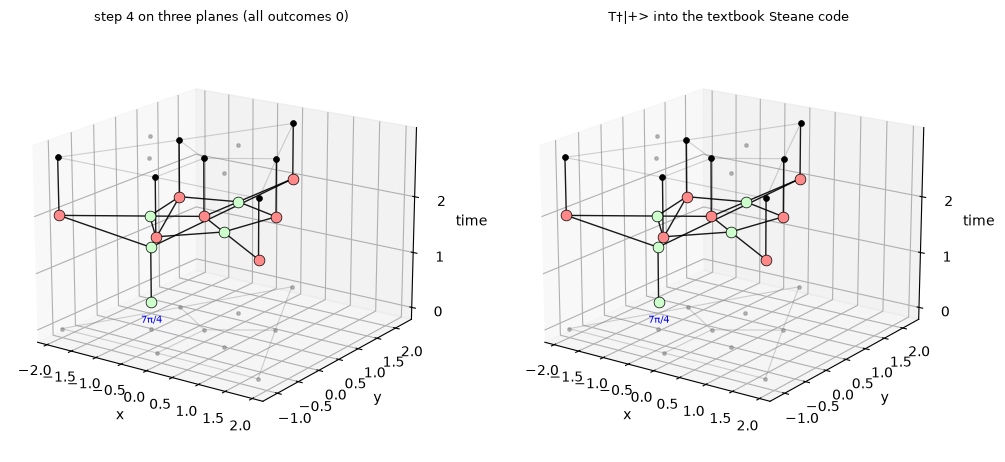

In [20]:
from pyzx.spacetime import set_timestep
from zxqec.spacetime import Topology, draw_graph_3d

# the triangle as a layout: the seven qubits, the sides of the faces, the middle of each face (node 7 + i),
# and a node outside the triangle for the logical spider and its state
size = 2.2
steane = Topology(2)
for q in range(7):
    steane.add_node(q, (size * POS[q][0], size * POS[q][1]))
for i, f in enumerate(FACES):
    for a, b in zip(f, f[1:] + f[:1]):
        if not steane.are_adjacent(a, b):
            steane.add_edge(a, b)
    steane.add_node(7 + i, tuple(sum(size * POS[q][k] for q in f) / 4 for k in range(2)))
LOGICAL = 10
steane.add_node(LOGICAL, (-1.5, 0.5))                                 # left of the side {0, 1, 3}

# step 4 on the nodes, its height as timestep: 0 the state, 1 the logical spider, 2 the code (X-spiders and S spiders)
planes = d3.copy()
xs = [next(iter(planes.neighbors(b))) for b in planes.outputs()]
for j, (b, x) in enumerate(zip(planes.outputs(), xs)):
    planes.set_qubit(b, on[qubits[j]])
    planes.set_qubit(x, on[qubits[j]])
    set_timestep(planes, x, 2)
for z in [v for v in planes.vertices() if planes.type(v) == VertexType.Z]:
    tri = frozenset(on[qubits[j]] for j, x in enumerate(xs) if planes.connected(z, x))
    if tri in faces:
        planes.set_qubit(z, 7 + faces.index(tri))                    # in the middle of its face, in the code's plane
        set_timestep(planes, z, 2)
    else:                                                            # L: outside the triangle, below the code
        planes.set_qubit(z, LOGICAL)
        set_timestep(planes, z, 1)
        state = planes.add_vertex(VertexType.Z, qubit=LOGICAL, phase=Fraction(7, 4))  # T-dag|+>, split off L
        planes.add_edge((state, z))
        planes.set_phase(z, planes.phase(z) - Fraction(7, 4))
        set_timestep(planes, state, 0)


def steane_t_dag(side):
    # T-dag|+> in the textbook Steane code, on the same nodes and heights: an X-spider on each qubit,
    # a Z-spider on each face and on one side (the logical X), and the state T-dag|+> under the latter
    t = Graph()
    xs, bs = {}, []
    for q in qubits:                                                 # outputs in the circuit's order
        n = on[q]
        xs[n] = t.add_vertex(VertexType.X, qubit=n)
        set_timestep(t, xs[n], 2)
        bs.append(t.add_vertex(VertexType.BOUNDARY, qubit=n))
        t.add_edge((xs[n], bs[-1]))
    for i, f in enumerate(FACES):
        s = t.add_vertex(VertexType.Z, qubit=7 + i)
        set_timestep(t, s, 2)
        for n in f:
            t.add_edge((s, xs[n]))
    l = t.add_vertex(VertexType.Z, qubit=LOGICAL)
    set_timestep(t, l, 1)
    for n in side:
        t.add_edge((l, xs[n]))
    state = t.add_vertex(VertexType.Z, qubit=LOGICAL, phase=Fraction(7, 4))
    set_timestep(t, state, 0)
    t.add_edge((state, l))
    t.set_inputs(())
    t.set_outputs(tuple(bs))
    return t


textbook = steane_t_dag([0, 1, 3])
zero = {n: 0 for n in variables}                                     # the run where every outcome is 0
step4_planes = planes.substitute_variables(zero)
fig = plt.figure(figsize=(12, 5.5))
for k, (d, title) in enumerate([(step4_planes, "step 4 on three planes (all outcomes 0)"),
                                (textbook, "T†|+> into the textbook Steane code")]):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    draw_graph_3d(d, steane, ax=ax, view=(18, -55))
    ax.set_title(title, fontsize=9)
fig

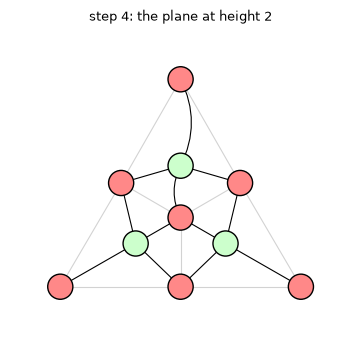

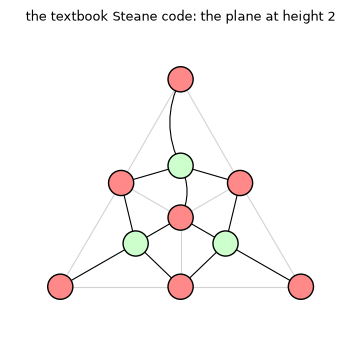

In [21]:
from zxqec.spacetime import draw_slice
display(draw_slice(step4_planes, steane, z=2, title="step 4: the plane at height 2", figsize=(4.5, 4)))
draw_slice(textbook, steane, z=2, title="the textbook Steane code: the plane at height 2", figsize=(4.5, 4))

**What to look at.** In the plane of the code (height 2) the seven qubits form the triangle, and each of `S1`, `S2`, `S3` sits in the middle of one face, wired to exactly its four corners: the slices show this alone. `L` sits below, outside the triangle next to the side {0, 1, 3}, and is wired to its three qubits; the T† state is below `L`. The pictures from the circuit and from the triangle have the same spiders and the same wires.

The next cell checks this. In the run where every outcome is 0, all the outcome phases of the table are 0, and step 4 is compared with the textbook diagram by tensor contraction, up to a scalar. Any other weight-3 logical X of the triangle (there are seven, the lines of the Fano plane) must give the same state, because the encoder depends on the logical X only up to stabilizers; the cell checks all seven. In the other runs step 4 carries the outcome phases of the table: π times a parity on an `S` spider is the sign of that face's X stabilizer, and on `L` it is the Z correction of Part 3.

In [22]:
print("all outcomes 0 is one of the", len(runs), "allowed runs:", zero in runs)
step4_zero = d3.substitute_variables(zero)
print("step 4 equal to the textbook diagram, up to a scalar:",
      zx.compare_tensors(step4_zero, textbook, preserve_scalar=False))

sides = [s for s in itertools.combinations(range(7), 3) if all(len(set(s) & set(f)) % 2 == 0 for f in FACES)]
print("weight-3 logical X operators of the triangle:", sides)
print("the same state with each of them:", [zx.compare_tensors(step4_zero, steane_t_dag(s), preserve_scalar=False)
                                            for s in sides])

all outcomes 0 is one of the 32 allowed runs: True
step 4 equal to the textbook diagram, up to a scalar: True
weight-3 logical X operators of the triangle: [(0, 1, 3), (0, 2, 5), (0, 4, 6), (1, 2, 6), (1, 4, 5), (2, 3, 4), (3, 5, 6)]
the same state with each of them: [True, True, True, True, True, True, True]


## Part 5. An independent check

The claims above come from the ZX pipeline. To check them without it, the next cell runs the **same Stim circuit** through a plain state-vector simulator (18 qubits; the simulator of our test suite, `tests/statevector.py`). It samples measurement outcomes with the correct probabilities, and in each run it tests:

1. every detector the authors wrote holds;
2. every stabilizer the tool reported has exactly the sign the tool predicts from that run's outcomes;
3. the logical Bloch vector, measured with the tool's logical operators, is T†|+⟩ after the tool's Pauli correction.

In [23]:
from tests.statevector import run, expectation
from zxqec.gpf import evaluate_phase

code = p.code_at(p.num_stages - 1).data()
q = [int(x) for x in code.qubits]
lx, lz = code.logical_x[0].letters, code.logical_z[0].letters
ly = ''.join({('X','Z'): 'Y', ('X','I'): 'X', ('I','Z'): 'Z', ('I','I'): 'I'}[(a, b)] for a, b in zip(lx, lz))
sign_y = (1j * (-1j) ** ly.count('Y')).real            # i * Xbar * Zbar = sign_y * (the string ly)
t_dag_plus = np.array([np.cos(np.pi / 4), -np.sin(np.pi / 4), 0.0])

rng = np.random.default_rng(2026); worst = 0.0; classes = []
for r in range(30):
    state, outs = run(circ, rng)
    a = {'c[{}]'.format(i): o for i, o in enumerate(outs)}
    assert all(sum(outs[int(n[2:-1])] for n in d) % 2 == 0 for d in circ.detectors)
    for st in code.stabilizers:
        want = (-1) ** (st.sign if isinstance(st.sign, int) else evaluate_phase(st.sign, a))
        worst = max(worst, abs(expectation(state, st.letters, q) - want))
    flip = (outs[4] + outs[5] + outs[6] + outs[7] + outs[14]) % 2
    classes.append(flip)
    bloch = np.array([expectation(state, lx, q).real, sign_y * expectation(state, ly, q).real, expectation(state, lz, q).real])
    worst = max(worst, float(np.abs(bloch - t_dag_plus * (np.array([-1, -1, 1]) if flip else 1)).max()))
print("30 sampled runs ({} with the Z correction): all 26 declared detectors held; largest deviation from "
      "the tool's predictions: {:.1e}".format(sum(classes), worst))

30 sampled runs (12 with the Z correction): all 26 declared detectors held; largest deviation from the tool's predictions: 2.2e-16


## Part 6. The same questions at d = 5

The protocol of Gidney, Shutty and Jones does not stop at d = 3. After the d = 3 double-check, the code is **grown** to the d = 5 colour code, with pairs of fresh qubits and Pauli corrections fed forward from measurements; it is checked for three rounds and then double-checked at d = 5.

Gidney et al.'s published circuits use S and S† in place of T and T†, so that Stim can simulate them. The circuit here has the real T gates. It comes from the repository `haoliri0/SOFT` (Apache-2.0) and uses Gidney et al.'s *unitary* injection, so its first stage differs from the d = 3 circuit above. It is kept as published, noise lines included (`program_from_stim` skips them), up to its noiseless final check, which is written for simulation and is not part of the protocol; see `circuits/cultivation/README.md`.

The stages are named after what they contain (counted below): one T† for the injection, 7 + 7 T-type gates for the d = 3 double-check, 17 fed-forward Paulis for the growth, three rounds of 18 checks, and 19 + 19 T-type gates for the d = 5 double-check. At d = 5 each half of the double-check mixes the two: the first half applies T to 6 of the code qubits and T† to the other 13, and the second half the inverse.

In [24]:
import time
from collections import Counter
from zxqec.qprogram import ParityControlled

text5 = open('circuits/cultivation/d5_cultivation.stim').read()
p5, circ5 = program_from_stim(text5, names=[
    'inject', 'double-check d=3 (T-dag, measure)', 'double-check d=3 (T, measure)', 'grow to d=5, checks',
    'checks', 'checks', 'double-check d=5 (first half)', 'double-check d=5 (second half)'])
print(circ5.qubits, "qubits,", circ5.measurements, "measurements,", len(circ5.detectors),
      "detectors written by the authors,", p5.num_stages, "stages")
for s in range(p5.num_stages):
    n = Counter(type(x).__name__ for x in p5.stage_circuit(s).gates)
    print(f"  stage {s} {p5.stage(s).name:<34} {n['T']:2} T-type gates, {n['Measurement']:2} measurements, "
          f"{n['ParityControlled']:2} fed-forward Paulis")

42 qubits, 93 measurements, 89 detectors written by the authors, 8 stages
  stage 0 inject                              1 T-type gates,  7 measurements,  0 fed-forward Paulis
  stage 1 double-check d=3 (T-dag, measure)   7 T-type gates,  1 measurements,  0 fed-forward Paulis
  stage 2 double-check d=3 (T, measure)       7 T-type gates, 11 measurements,  0 fed-forward Paulis
  stage 3 grow to d=5, checks                 0 T-type gates, 18 measurements, 17 fed-forward Paulis
  stage 4 checks                              0 T-type gates, 18 measurements,  0 fed-forward Paulis
  stage 5 checks                              0 T-type gates, 18 measurements,  0 fed-forward Paulis
  stage 6 double-check d=5 (first half)      19 T-type gates,  1 measurements,  0 fed-forward Paulis
  stage 7 double-check d=5 (second half)     19 T-type gates, 19 measurements,  0 fed-forward Paulis


### Question 1: the code after each stage

In [25]:
t0 = time.perf_counter()
for s in range(p5.num_stages):
    blocks = p5.code_at(s).blocks()
    print("after stage {} ({}): ".format(s, p5.stage(s)) + "; ".join("[[{},{},{}]]{}".format(
          *b.parameters, " (non-Clifford logical state)" if b.non_clifford else "") for b in blocks))
print(f"({time.perf_counter() - t0:.1f} s for the eight stages)")

after stage 0 (inject): [[7,1,3]] (non-Clifford logical state)
after stage 1 (double-check d=3 (T-dag, measure)): [[12,3,2]] (non-Clifford logical state)


after stage 2 (double-check d=3 (T, measure)): [[7,1,3]] (non-Clifford logical state); [[2,0,None]]; [[2,0,None]]; [[2,0,None]]; [[2,0,None]]; [[2,0,None]]; [[2,0,None]]


after stage 3 (grow to d=5, checks): [[19,1,5]] (non-Clifford logical state)


after stage 4 (checks): [[19,1,5]] (non-Clifford logical state)


after stage 5 (checks): [[19,1,5]] (non-Clifford logical state)


after stage 6 (double-check d=5 (first half)): [[37,9,None]] (non-Clifford logical state)


after stage 7 (double-check d=5 (second half)): [[19,1,5]] (non-Clifford logical state)
(3.1 s for the eight stages)


* After the **injection**: the [[7,1,3]] code with a non-Clifford logical state, as at d = 3.
* In the **middle of each double-check** the cut falls inside the T†…T sandwich, and the tool reports codes that are not useful there: [[12,3,2]], as in Part 1, and at d = 5 a code on 37 qubits with 9 logical qubits (its distance is not computed).
* After the **d = 3 double-check**: the [[7,1,3]] code again, next to six pairs of qubits in a joint stabilizer state with no logical qubit (`[[2,0]]`), which the growth uses.
* After the **growth** and after each round of checks: a **[[19,1,5]]** code holding a non-Clifford logical state, the d = 5 colour code of the protocol.
* After the **d = 5 double-check**: the [[19,1,5]] code again.

The stabilizers at the end, with signs that are outcomes. The sign `c[21]` is always 0; see below.

In [26]:
print(p5.code_at(p5.num_stages - 1).data())

[[19, 1, 5]] CSS code on qubits 0, 3, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 32, 34, 36, 38, 40 (holding a non-Clifford logical state)
    stabilizer (-1)^(c[76])XIIXXXIIIIIIIIIIIII
    stabilizer (-1)^(c[75])IIIIIIXIIXXIIXIIIII
    stabilizer (-1)^(c[74])IIIIIIXIIIXIXIIXIII
    stabilizer (-1)^(c[80])IIIIIIIXIIIXIIIIIXX
    stabilizer (-1)^(c[81])IIIIIIIIIIIIIIXIXXX
    stabilizer (-1)^(c[11] + c[78] + c[10] + c[79])XXXIXIIIIIIIIIIIIII
    stabilizer +XIIIXIIIXXXIIIIXIII
    stabilizer +IIIIIIXXXIXIIIIIXXI
    stabilizer (-1)^(c[10] + c[79])XIXXIIIIXIIIIIIIIXX
    stabilizer +ZZZIZIIIIIIIIIIIIII
    stabilizer +ZIIZZZIIIIIIIIIIIII
    stabilizer +IIIIIIZIIZZIIZIIIII
    stabilizer +IIIIIIIZIIIZIIZIZII
    stabilizer +IIIIIIIZIIIZIIIIIZZ
    stabilizer (-1)^(c[21])IIIIIIZIIIZIZIIZIII
    stabilizer +ZZIIIZIZZIIZIIIIIII
    stabilizer +ZIIIZIZIZZIIZIIIIII
    stabilizer +IIIIIIZZZIZIIIZIIIZ
    logical X XXIXIIXIIIXIIIIIIII   logical Z ZZIZIIZIIIZIIIIIIII


### Detectors, and what the whole circuit does

In [27]:
t0 = time.perf_counter()
print(check_detectors(p5, circ5.detectors))
print(f"({time.perf_counter() - t0:.1f} s)")
print()
print(p5.logical_action().describe())

89 declared detector(s): 89 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 89 independent detectors on its results, all sums of declared ones
(0.9 s)



logical action: 0 -> 1 logical qubit(s)
  in every run: prepares T^dag|+>
  deterministic: every run implements prepares T^dag|+>


**In every noiseless run, the d = 5 circuit prepares T†|+⟩ in the [[19,1,5]] code**, the same operation in every run: unlike d = 3 (Part 3), no Pauli correction of the logical qubit depends on the outcomes. All 89 detectors the authors wrote are derived, and no others.

### The corrections of the growth

The growth (stage 3) measures qubits and feeds Pauli corrections forward from the outcomes. They act before the T-type gates of the d = 5 double-check. Moving an X through a T turns the T into a T† (T X = e^{iπ/4} X T†), so in the diagram an outcome that controls an X sits on the hubs of gadgets and decides their signs.

Of the outcomes that control an X, `c[21]`, `c[23]` and `c[25]` are always 0 in a noiseless run: the authors wrote a detector on each of them alone, and the tool derives these too. `reduce_gpf` puts such values into the hubs before it simplifies the gadget layer. Without that step, these outcomes would keep apart gadgets that cancel in every run that can occur, and the code after the d = 5 double-check would seem to depend on them.

In [28]:
fed = [x for x in p5.stage_circuit(3).gates if isinstance(x, ParityControlled)]
print(len(fed), "Paulis fed forward in stage 3:", ", ".join(map(str, fed)))
g5 = p5.quantum_graph()
res5 = reduce_gpf(g5, gadgets=False)                       # reduced, with the gadgets held fixed
fixed = {str(c) for c in res5.constraints if len(c.free_vars()) == 1}
x_controls = sorted({b for x in fed if x.gate == 'X' for b in x.bits})
print("outcomes that control an X:", x_controls, "| of these, fixed to 0 by the detectors:",
      [b for b in x_controls if b in fixed])

17 Paulis fed forward in stage 3: if(c[31]) Z(36), if(c[31]) Z(40), if(c[33]) Z(15), if(c[33]) Z(23), if(c[22]) X(36), if(c[22]) X(40), if(c[22]) X(38), if(c[22]) X(40), if(c[21]) X(36), if(c[21]) X(40), if(c[25]) X(15), if(c[25]) X(23), if(c[24]) X(0), if(c[24]) X(11), if(c[24]) X(23), if(c[23]) X(15), if(c[23]) X(23)


outcomes that control an X: ['c[21]', 'c[22]', 'c[23]', 'c[24]', 'c[25]'] | of these, fixed to 0 by the detectors: ['c[21]', 'c[23]', 'c[25]']


### The 53 T-type gadgets in the code's variables

As in step 2 of Part 4, write the normal form in the code's variables: the logical X (`L`), the nine X-type generators (`S1` to `S9`) of the code above, and the combinations of Z-spiders that reach no output (the hidden variables `h1`, `h2`, ...). The phases are first written modulo the detectors (`phases_modulo`), so `c[21]`, `c[23]` and `c[25]` become 0. There are 53 gadgets: the T† of the injection, 14 from the d = 3 double-check and 38 from the d = 5 double-check.

In [29]:
code5 = p5.code_at(p5.num_stages - 1).data()
rows5 = [list(code5.logical_x[0].x)] + [list(r) for r in code5.sx]
m5 = change_variables(phases_modulo(res5.graph, res5.constraints), rows5, fuse=False)
zs5 = sorted(v for v in m5.vertices() if m5.type(v) == VertexType.Z and not is_leaf(m5, v))
var5 = dict(zip(zs5, ['L'] + ['S{}'.format(i + 1) for i in range(len(code5.sx))]
                + ['h{}'.format(i + 1) for i in range(len(zs5) - len(rows5))]))
poly5, gadgets5 = phase_polynomial(m5)
print(len(gadgets5), "gadgets; Z-spiders:", ' '.join(var5[z] for z in zs5))
print("phase polynomial (units of pi):",
      {'*'.join(sorted(var5[v[1]] if isinstance(v, tuple) else v for v in m)): str(c) for m, c in poly5.items() if c % 2})
hidden = {var5[z]: m5.phase(z) for z in zs5 if var5[z].startswith('h')}
print("phases of the hidden variables:", {name: str(ph) for name, ph in hidden.items()})
print()

names5 = ['c[{}]'.format(i) for i in range(circ5.measurements)]
on_outcomes = [d for d in res5.detectors if all(str(v).startswith('c[') for v in d.free_vars())]
before = span(on_outcomes, names5)                                   # span() and rank() from Part 2
with_hidden = np.concatenate([before, span(list(hidden.values()), names5)])
declared = span(circ5.detectors, names5)
print("detectors on outcomes with the gadgets held fixed:", rank(before),
      "| with the phases of the hidden variables:", rank(with_hidden),
      "| the same space as the authors' 89:", rank(with_hidden) == rank(declared) == rank(np.concatenate([with_hidden, declared])))
r5 = reduce_gpf(g5)
print("reduce_gpf with the gadget step, in the circuit's own variables:", len(gadgets5), "gadgets ->",
      sum(1 for v in r5.graph.vertices() if is_leaf(r5.graph, v)))

53 gadgets; Z-spiders: L S1 S2 S3 S4 S5 S6 S7 S8 S9 h1 h2 h3 h4 h5 h6 h7 h8 h9 h10 h11 h12 h13
phase polynomial (units of pi): {'L': '7/4'}
phases of the hidden variables: {'h1': 'c[7]', 'h2': 'c[10]', 'h3': 'c[10] + c[35]', 'h4': 'c[10] + c[34]', 'h5': 'c[10] + c[36]', 'h6': 'c[10] + c[53]', 'h7': 'c[10] + c[52]', 'h8': 'c[10] + c[54]', 'h9': 'c[10] + c[71]', 'h10': 'c[10] + c[70]', 'h11': 'c[10] + c[72]', 'h12': 'c[10] + c[73]', 'h13': 'c[10] + c[73] + c[74]'}

detectors on outcomes with the gadgets held fixed: 76 | with the phases of the hidden variables: 89 | the same space as the authors' 89: True


reduce_gpf with the gadget step, in the circuit's own variables: 53 gadgets -> 25


All 53 T-type gadgets add up to **7π/4 on `L`**: one T† gadget on the logical variable, as at d = 3 (Part 4, step 2). Nothing else is left, not even a Pauli term, because the phases were written modulo the detectors. The 13 hidden variables reach no output and carry Pauli phases only, so the sum over each of them is a detector. These 13 are the detectors that the reduction misses when it holds the gadgets fixed; with them, the derived detectors are exactly the 89 the authors wrote.

`reduce_gpf` by itself stops at 25 gadgets. Its gadget step adds the gadgets up in the variables it is given and does not look for the code's variables. The answers above do not need the single gadget: `code_of` reads a code through a layer of gadgets with its phase-polynomial test.

### The authors' final check

The published file ends with a check of the output state that the authors wrote for simulation (`circuits/cultivation/d5_final_check.stim`, the file's last 25 lines). It measures the 18 stabilizers of the colour code as products of Paulis (`MPP`), with a `DETECTOR` for each, then applies a layer of T and T† gates and measures the product of Y on the 19 code qubits. That last result, together with 10 outcomes of the d = 5 double-check, is the file's `OBSERVABLE_INCLUDE(0)`: the logical result the authors expect to be the same in every noiseless run.

`program_from_stim` measures each product of Paulis with a helper qubit of its own. Here the protocol is read again with the final check after it, which is the published file line for line.

In [30]:
final_check = open('circuits/cultivation/d5_final_check.stim').read()
p5c, circ5c = program_from_stim(text5 + final_check)
print(circ5c.measurements, "measurements,", len(circ5c.detectors), "detectors written by the authors, observable 0 on",
      len(circ5c.observables[0]), "results")
t0 = time.perf_counter()
print(check_detectors(p5c, circ5c.detectors))
print("observable 0:", check_detectors(p5c, [circ5c.observables[0]]).declared[0])
print(f"({time.perf_counter() - t0:.1f} s)")

112 measurements, 107 detectors written by the authors, observable 0 on 11 results


107 declared detector(s): 107 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 108 independent detectors on its results; 1 of them is not sums of declared ones, e.g.:
  c[111] = 0


observable 0: detector 0: c[83] + c[84] + c[85] + c[86] + c[87] + c[88] + c[89] + c[90] + c[91] + c[92] + c[111] = 0 in every run
(3.0 s)


**The circuit passes the authors' own check in every noiseless run**: all 107 detectors are deterministic, the 18 of the final check included, and so is the observable, with value 0. The tool also derives one detector that the authors did not write: `c[111]`, the product of Y after the layer of T gates, is 0 on its own; the authors use it only inside the observable.

### The result in 3D, next to the colour code of the authors' final check

At d = 3 the reduced diagram was drawn on the triangle of the Steane code and compared with T†|+⟩ in the textbook Steane code. At d = 5 the colour code to compare with comes from the published file itself: the final check above measures the 18 stabilizers of the code on the **faces** of the triangle, 6 squares and 3 hexagons, each once as X and once as Z. The authors wrote these independently of the tool, and the file also gives every qubit's coordinates.

First, the code that the tool read off the circuit (Question 1) has exactly these stabilizers.

In [31]:
from zxqec.codes import PauliString

# the faces of the triangle, as the first MPP of the final check measures them: each once as a product of X and once
# as a product of Z
first_mpp = next(ins for ins in circ5c.instructions if ins.name == 'MPP')
FACES5 = [[int(f[1:]) for f in t.split('*')] for t in first_mpp.targets if t.startswith('X')]
print(len(FACES5), "faces; the Z products are on the same faces:", sorted(map(sorted, FACES5)) ==
      sorted(sorted(int(f[1:]) for f in t.split('*')) for t in first_mpp.targets if t.startswith('Z')))
SIDE5 = [0, 3, 9, 15, 23]                                            # one side of the triangle
qubits5 = [int(q) for q in code5.qubits]                             # the outputs, in order
on5 = lambda support: [int(q in support) for q in qubits5]
faces_xz = ([PauliString.from_arrays(on5(f), [0] * code5.n) for f in FACES5]
            + [PauliString.from_arrays([0] * code5.n, on5(f)) for f in FACES5])
print("every face, as an X and as a Z stabilizer, is in the code read off the circuit:", all(code5.contains(s) for s in faces_xz))
print("independent ones:", rank(np.array([s.symplectic for s in faces_xz], dtype=np.uint8)),
      "| generators of the code:", len(code5.stabilizers))
print("the side is the code's logical X:", on5(SIDE5) == [int(b) for b in code5.logical_x[0].x])

9 faces; the Z products are on the same faces: True
every face, as an X and as a Z stabilizer, is in the code read off the circuit: True
independent ones: 18 | generators of the code: 18
the side is the code's logical X: True


So the code is that colour code, and the side is its logical X. Now write the reduced diagram in the variables of the side and the nine faces (`change_variables`, as in Part 4, step 4), add its gadgets up in these variables (`simplify_gadgets`), and fuse what is left.

In [32]:
from zxqec.gpf import simplify_gadgets

rows_f = [on5(SIDE5)] + [on5(f) for f in FACES5]
m5f = change_variables(r5.graph, rows_f, fuse=False)      # the reduced diagram (r5 above) in the faces' variables
while simplify_gadgets(m5f):                               # its 25 gadgets, added up in these variables
    pass
m5f = change_variables(m5f, rows_f)                        # fuses a gadget left on a single spider
shown = phases_modulo(m5f, r5.constraints)
xs5 = [next(iter(shown.neighbors(b))) for b in shown.outputs()]
print(sum(1 for v in shown.vertices() if is_leaf(shown, v)), "gadgets left")
for z in [v for v in shown.vertices() if shown.type(v) == VertexType.Z]:
    print("  Z-spider with phase {:4}  wired to qubits {}".format(
          str(shown.phase(z)), [q for q, x in zip(qubits5, xs5) if shown.connected(z, x)]))
print("phases that depend on outcomes, modulo the detectors:",
      [str(shown.phase(v)) for v in shown.vertices() if getattr(shown.phase(v), 'free_vars', lambda: [])()] or 'none')

0 gadgets left
  Z-spider with phase 7/4   wired to qubits [0, 3, 9, 15, 23]
  Z-spider with phase 0     wired to qubits [0, 3, 7, 11]
  Z-spider with phase 0     wired to qubits [9, 13, 15, 19, 21, 27]
  Z-spider with phase 0     wired to qubits [17, 25, 32, 36]
  Z-spider with phase 0     wired to qubits [3, 7, 9, 13]
  Z-spider with phase 0     wired to qubits [15, 21, 23, 29]
  Z-spider with phase 0     wired to qubits [19, 25, 27, 32, 34, 38]
  Z-spider with phase 0     wired to qubits [7, 11, 13, 17, 19, 25]
  Z-spider with phase 0     wired to qubits [21, 27, 29, 34]
  Z-spider with phase 0     wired to qubits [32, 36, 38, 40]
phases that depend on outcomes, modulo the detectors: none


The diagram is the logical spider with 7π/4, wired to the side, and one spider per face wired to exactly that face. Drawn as at d = 3, with the library's 3D view (`draw_graph_3d`) on a `Topology`:

* **height 0**: the state T†|+⟩, split off the logical spider;
* **height 1**: the logical spider `L`, on a node outside the triangle, beyond the side it is wired to;
* **height 2**: the code: the 19 output X-spiders, at the coordinates the file gives the qubits, and each face spider in the middle of its face (the outputs end at height 3).

Left: the reduced diagram above. Right: T†|+⟩ fed into the colour code built from the faces and the side alone (`textbook5`), in the same way as the textbook Steane code at d = 3. Below them, the plane at height 2 of each, flat (`draw_slice`): the colour code alone.

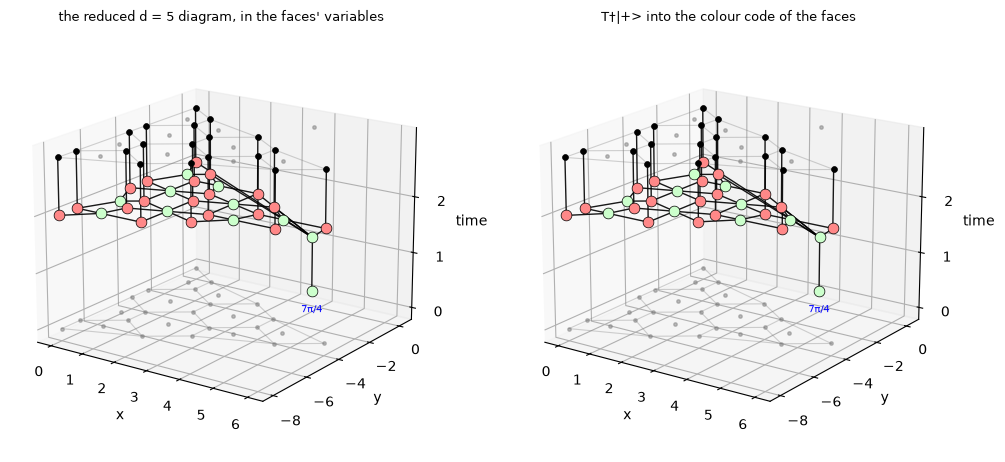

In [33]:
import math
from pyzx.graph import Graph
from pyzx.spacetime import set_timestep
from zxqec.spacetime import Topology, draw_graph_3d

# the layout: the 19 code qubits at the coordinates of the file (drawn as in the d = 3 layout plot), the sides of the
# faces, a node in the middle of each face (100 + i), and a node outside the triangle beyond SIDE5, for L and its state
xy5 = {q: (circ5.coords[q][1], -circ5.coords[q][0]) for q in qubits5}
middle = lambda qs: tuple(sum(xy5[q][k] for q in qs) / len(qs) for k in range(2))
tri5 = Topology(2)
for q in qubits5:
    tri5.add_node(q, xy5[q])
for i, f in enumerate(FACES5):
    c = middle(f)
    ring = sorted(f, key=lambda q: math.atan2(xy5[q][1] - c[1], xy5[q][0] - c[0]))     # around the face
    for a, b in zip(ring, ring[1:] + ring[:1]):
        if not tri5.are_adjacent(a, b):
            tri5.add_edge(a, b)
    tri5.add_node(100 + i, c)
side_mid, rest = middle(SIDE5), middle([q for q in qubits5 if q not in SIDE5])
LOGICAL5 = 200
tri5.add_node(LOGICAL5, tuple(side_mid[k] + 2.4 * (side_mid[k] - rest[k]) / math.dist(side_mid, rest) for k in range(2)))


def textbook5(angle=Fraction(7, 4)):
    # the colour code built from FACES5 and SIDE5 alone: an X-spider on each qubit, a Z-spider on each face and on
    # the side (the logical X), and the state with this angle under the latter; T-dag|+> by default
    t = Graph()
    xs, bs = [], []
    for q in qubits5:                                                # outputs in the circuit's order
        xs.append(t.add_vertex(VertexType.X))
        bs.append(t.add_vertex(VertexType.BOUNDARY))
        t.add_edge((xs[-1], bs[-1]))
    for support in FACES5 + [SIDE5]:
        s = t.add_vertex(VertexType.Z)
        for q in support:
            t.add_edge((s, xs[qubits5.index(q)]))
    t.add_edge((t.add_vertex(VertexType.Z, phase=angle), s))         # s is the spider of the side
    t.set_inputs(())
    t.set_outputs(tuple(bs))
    return t


def on_planes(d):
    # heights: 0 the state, 1 L (outside), 2 the code: the X-spiders and the face spiders (in the middle of their faces)
    d = d.copy()
    xs = [next(iter(d.neighbors(b))) for b in d.outputs()]
    for q, b, x in zip(qubits5, d.outputs(), xs):
        d.set_qubit(b, q)
        d.set_qubit(x, q)
        set_timestep(d, x, 2)
    for z in [v for v in d.vertices() if d.type(v) == VertexType.Z and any(w in xs for w in d.neighbors(v))]:
        wired = sorted(qubits5[j] for j, x in enumerate(xs) if d.connected(z, x))
        if wired != sorted(SIDE5):
            d.set_qubit(z, 100 + [sorted(f) for f in FACES5].index(wired))
            set_timestep(d, z, 2)
            continue
        d.set_qubit(z, LOGICAL5)
        set_timestep(d, z, 1)
        if d.phase(z) != 0:                                          # split the state off L, as at d = 3
            d.add_edge((d.add_vertex(VertexType.Z, phase=d.phase(z)), z))
            d.set_phase(z, 0)
        for state in [w for w in d.neighbors(z) if d.vertex_degree(w) == 1]:
            d.set_qubit(state, LOGICAL5)
            set_timestep(d, state, 0)
    return d


fig = plt.figure(figsize=(12, 5.5))
for k, (d, title) in enumerate([(shown, "the reduced d = 5 diagram, in the faces' variables"),
                                (textbook5(), "T†|+> into the colour code of the faces")]):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    draw_graph_3d(on_planes(d), tri5, ax=ax, view=(18, -55))
    ax.set_title(title, fontsize=9)
fig

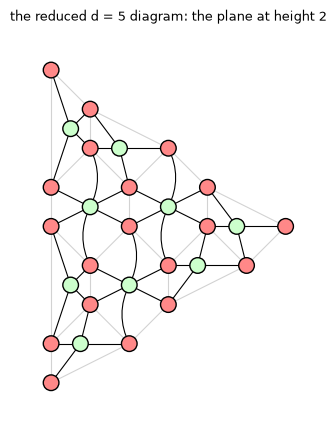

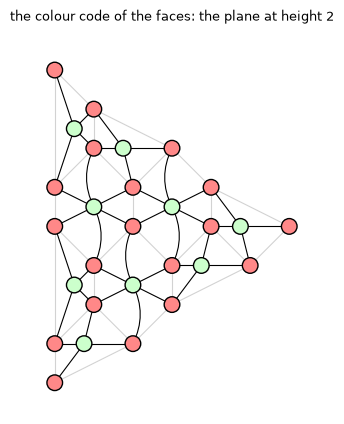

In [34]:
from zxqec.spacetime import draw_slice
display(draw_slice(on_planes(shown), tri5, z=2, title="the reduced d = 5 diagram: the plane at height 2", figsize=(6, 5)))
draw_slice(on_planes(textbook5()), tri5, z=2, title="the colour code of the faces: the plane at height 2", figsize=(6, 5))

The two have the same spiders and the same wires. The next cell checks this by tensor contraction (`same_map`, which uses no rewrite of ours), first for the reduced diagram and then for **the whole circuit**, run by run.

In [35]:
import random
from zxqec.gpf import boolean_variables, consistent_assignments, evaluate_phase, same_map, sample_consistent_assignment

variables5 = sorted(set(boolean_variables(g5)) | {str(v) for c in r5.constraints for v in c.free_vars()})
zero5 = {n: 0 for n in variables5}
print(len(variables5), "Boolean variables;", len(consistent_assignments(r5.constraints, variables5)),
      "runs allowed by the detectors; all outcomes 0 is one of them:", all(evaluate_phase(c, zero5) == 0 for c in r5.constraints))
print("the reduced diagram equals T†|+> in the colour code of the faces:", same_map(shown.substitute_variables(zero5), textbook5()))
print("... and differs from T|+> in the same code:", not same_map(shown.substitute_variables(zero5), textbook5(Fraction(1, 4))))
print()
rng = random.Random(2026)
for a in [zero5] + [sample_consistent_assignment(r5.constraints, variables5, rng) for _ in range(3)]:
    t0 = time.perf_counter()
    same = same_map(g5.substitute_variables(a), textbook5())
    print("the whole circuit, in a run with {:2} outcomes equal to 1, equals T†|+> in the colour code of the faces: {}  ({:.0f} s)"
          .format(sum(a[n] for n in a if n.startswith('c[')), same, time.perf_counter() - t0))

127 Boolean variables; 1024 runs allowed by the detectors; all outcomes 0 is one of them: True


the reduced diagram equals T†|+> in the colour code of the faces: True


... and differs from T|+> in the same code: True



the whole circuit, in a run with  0 outcomes equal to 1, equals T†|+> in the colour code of the faces: True  (24 s)


the whole circuit, in a run with  3 outcomes equal to 1, equals T†|+> in the colour code of the faces: True  (18 s)


the whole circuit, in a run with  3 outcomes equal to 1, equals T†|+> in the colour code of the faces: True  (6 s)


the whole circuit, in a run with  1 outcomes equal to 1, equals T†|+> in the colour code of the faces: True  (20 s)


**What this shows.** The code read off the circuit is the colour code whose faces the authors measure in their final check. In the faces' variables the reduced diagram is exactly T†|+⟩ fed into that code: the logical spider carries 7π/4 and is wired to one side of the triangle, and each face spider is wired to its face. No outcome is left on any spider (modulo the detectors), so the picture is the same in every run. Unlike at d = 3, the comparison needs no search over orderings of the qubits, because the faces and the coordinates come with the file.

The last lines check the circuit itself, not only its reduction. For one run at a time, PyZX contracts the whole circuit diagram (after its own simplification the diagram is small enough for this: a median of 18 s per run, up to about half an hour for a few), and it equals T†|+⟩ in the colour code of the faces. The notebook checks 4 of the 1024 runs that the detectors allow; `cultivation_d5_all_runs.py` checks all 1024 (about nine hours on a laptop), and `tests/test_cultivation.py` the run where every outcome is 0.

**What is still not checked at d = 5.** There is no independent simulation as in Part 5, because the circuit has 42 qubits.

## Summary

| question | the tool's answer | checked by |
|---|---|---|
| which code? | [[7,1,3]] colour code after injection and after the double-check, signs given by outcomes | simulation: each stabilizer has the predicted sign |
| detectors | all 26 the authors wrote, and no others; two of them need the gadget layer | comparison with the authors' `DETECTOR` lines |
| what does it do? | prepares T†\|+⟩, with a Z correction on a known parity of outcomes | simulation: the logical Bloch vector |
| the double-check | a logical measurement in {T†\|+⟩, T†\|−⟩}, whose outcome is predicted by the injection outcomes | measurement report; simulation |
| the reduction, drawn | circuit → normal form with 15 gadgets → one T† gadget → T†\|+⟩ into the encoder of the colour code | every picture contracted against the circuit, in all 32 allowed runs |
| the result, in 3D | the four Z-spiders sit on the three faces and one side of the Steane triangle | contracted against T†\|+⟩ in the textbook Steane code, built from the triangle (all outcomes 0) |
| d = 5, real T (Part 6) | [[19,1,5]] code after the growth and after the d = 5 double-check; prepares T†\|+⟩ in every run; all 89 detectors the authors wrote, and no others; in the code's variables the 53 T-type gadgets are one T† gadget on the logical variable | comparison with the authors' `DETECTOR` lines |
| d = 5, the authors' final check | all 107 detectors (18 of them from the final check) and the observable are deterministic, value 0 | the authors' own check, run through the tool |
| d = 5, in 3D | in the variables of the faces of the final check, the reduced diagram is T†\|+⟩ into the colour code of those faces, the same in every run | contracted against that state, built from the faces alone; the whole circuit too, in 4 of its 1024 allowed runs here and in all 1024 with `cultivation_d5_all_runs.py` |

Noise is left out on purpose. How often cultivation rejects a state, and how good the accepted states are, need a simulation of the noisy circuit, and simulating a circuit with T gates takes exponential time in general. Other libraries do that: Stim for the version with S in place of T, and the few-Clifford-terms simulator of Wan, Zhong and Zapirain for real T. This library answers noiseless questions by rewriting, which takes polynomial time except in three places, each exponential in a number that is small here: the gadget test (in the number of independent gadget parities), the classes of runs (in the number of phases left) and presenting a code (in the number of its generators). Nothing here goes beyond d = 5, and at d = 5 there is no independent simulation.